In [4]:
import astropy as ast #for constants etc
import astropy.constants as cst #constants 
import numpy as np
import matplotlib.pyplot as plt
import scipy as sci

# Following similar procedure as to in 'Neutron stars for undergraduates'
# Richard R. Silbar; Sanjay Reddy (2004)
# https://doi.org/10.1119/1.1703544
# the ratio of Z/A = 2 

##################################################################

c = cst.c.value # speed of light 
atomic_ratio = 2 
m_N = (cst.m_n.value + cst.m_p.value)/2
gamma = 5/3
R_0 = (cst.G.value * cst.M_sun.value) / (c**2)
eps_0 = 0.013



def K_nr(eps_0):
    return (cst.hbar.value**2) / (15 *np.pi**2 * cst.m_e.value) * ((3 * np.pi * (1/atomic_ratio) / (m_N * c**2))**(5/3))

def beta_nr(eps_0):
    return (4 * np.pi * eps_0)/(cst.M_sun.value * c**2 * (K_nr(eps_0) * eps_0**(gamma - 1)**(1/gamma)))

def alpha_nr(eps_0):
    return R_0 / ((K_nr(eps_0) * eps_0**(1/gamma))**(1 - gamma))


def dH_dr(t, eqns, Gamma, Alpha, Beta, eps_0):
    Arr = [(-Alpha(eps_0) * eqns[1]** (1/Gamma) * eqns[0]) / t**2 , 
            Beta(eps_0) * t**2 * (eqns[1])**(1/Gamma)]
    return np.array(Arr)

##################################################################



# 8900km WD 1Sol mass

# A2 poster
# Non specialised audinece 



# there's enough there toa ask about if you're stood there

/tmp/ipykernel_312710/2138995484.py:21: RuntimeWarning: invalid value encountered in scalar power
  coupling = np.array([- (fns[1] ** n) * t**2, fns[0]/(t**2)])


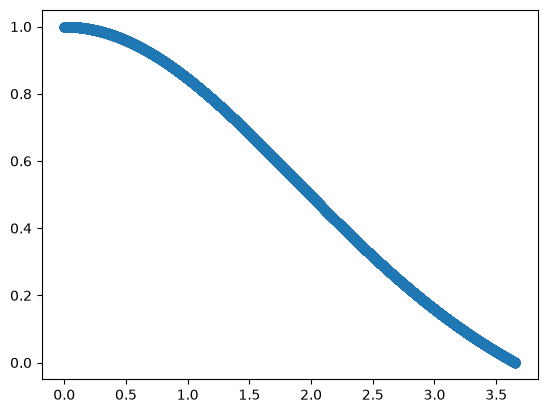

UnboundLocalError: cannot access local variable 'step_size_interpolation' where it is not associated with a value

In [7]:
import astropy as ast #for constants etc
import astropy.constants as cst #constants 
import numpy as np
import matplotlib.pyplot as plt
import scipy as sci
import numba

# Following similar procedure as to in 'Neutron stars for undergraduates'
# Richard R. Silbar; Sanjay Reddy (2004)
# https://doi.org/10.1119/1.1703544
# the ratio of Z/A = 2 

## Runga-kutta explicit method 
# fns = [u(theta(xi)), theta(xi)]

# Note: AI (Claude Sonnet 5.5) on low setting was used to assist in debugging the Runga-Kutta 4(5) 

X = np.array([0., 1.]) # these are initial conditions 

def Lane_Emden(t, fns, n): # this takes inputs [theta' = >>>>>u /xi^2<<<<<< , >>>>-theta^n * xi^2<<<<< = u']
    coupling = np.array([- (fns[1] ** n) * t**2, fns[0]/(t**2)])
    return coupling 


def RK4(f, initial_conditions, initial_radius, dxi, n_steps, n):
    con = np.zeros((n_steps + 1, 2))
    con[0] = initial_conditions # the initial conditions (must be an array)

    for i in range (0, n_steps):
        k_1 = f(initial_radius + i*dxi, con[i],  n )
        N_2 = con[i] + (k_1*dxi/2)
        k_2 = f((initial_radius + i*dxi+dxi/2), N_2, n )
        N_3 = con[i] + (k_2*dxi/2)
        k_3 = f( initial_radius + i*dxi+dxi/2, N_3,  n )
        N_4 = con[i] + (k_3*dxi)
        k_4 = f(initial_radius + i*dxi+dxi, N_4,  n )
        k = 1/6 * (k_1 + 2*k_2 + 2*k_3 + k_4)
        con[i+1] = (con[i] + dxi * k)
    return con # this integrates ( in general [f(t), g(t)] ), but in our case integrates [u /xi^2, -theta^n * xi^2] 



steps = 400000
infintesimal = 0.0001
order_n = 1
initial_radius = 0.00000000000000001 
ns = [3/2]


plt.figure()


for k in range(len(ns)):
    solved = RK4(Lane_Emden, X, initial_radius, infintesimal, steps, n = ns[k])
    plt.scatter(initial_radius + infintesimal * np.arange(steps + 1), solved[:,1])

ax = plt.gca()

plt.show()

def linear_line(grad, intercept, x):
    return grad * x + intercept

def zero_finder(xs, ys, dxi): # this uses a linear interpolation 
    positive_values = np.where(solved[:,1] > 0) # array of the position all y values greater than 0 
    last_positive = np.array(positive_values)[0][-1] # the position of the last positive y value 
    dy = ys[last_positive-1] - ys[last_positive-2]
    dx = xs[last_positive-1] - xs[last_positive-2]
    gradient = dy/dx
    intercept = ys[last_positive-1]
    
    k = 0
    interpolation = np.zeros(1000)
    
    interpolation[0] = ys[last_positive]

    
    last_positive_x = xs[last_positive]

    while interpolation[k] > 0:
        step_size_interpolation = dxi / 100
        interpolation[k + 1] = linear_line(gradient, intercept, last_positive_x + (step_size_interpolation * k) )
        k += 1 
        if k > 10000:
            print('While loop too long')
            break
    zero_middle_position = ((last_positive_x + step_size_interpolation * (k + 1)) + (last_positive_x + step_size_interpolation * k)) / 2 
    return zero_middle_position
        
################################################################################################################################################################
# Finding the mass radius relation 
################################################################################################################################################################

xi_1 = zero_finder(initial_radius + infintesimal * np.arange(steps + 1), solved[:,1], infintesimal)

print(xi_1)

theta_prime_1 = zero_finder(initial_radius + infintesimal * np.arange(steps + 1), solved[:,0], infintesimal ) # this is theta'(xi) = u / xi^2

K_nr = (cst.hbar.value**2) / (15 *math.pi**2 * cst.m_e.value) * ((3 * math.pi * (1/atomic_ratio) / (m_N * c**2))**(5/3))



Mass_constants = 4 * math.pi * (((n + 1) * K_nr)/ (4 * math.pi * cst.G.value))**(3/2) * (eps_0 * cst.c.value ** 2 )**((3-n)/2*n)

MASS = Mass_constants * (eps_0 ** ((3-n)/2) * (solved.y[1] **2) * abs(solved.y[0]))

Radius_constants = (((n + 1) * K_nr)/ (4 * math.pi * cst.G.value))**(1/2) 
RADIUS = Radius_constants * eps_0 ** ((1-n)/2*n) * solved.y[0]

plt.scatter(MASS,RADIUS)


In [ ]:
#######################################################
            # >>>> Using solve_ivp <<<< #
#######################################################
import astropy as ast #for constants etc
import astropy.constants as cst #constants 
import numpy as np
import matplotlib.pyplot as plt
import scipy as sci
import math

X = np.array([0., 1.]) # these are initial conditions 


ns = 3
def Lane_Emden(t, fns, n):
    coupling = np.array([- (fns[1] ** n) * t**2, fns[0]/(t**2)])
    return coupling

solved = sci.integrate.solve_ivp(Lane_Emden, [0.000000000000000000001, 10], X, args = (ns,), max_step = 0.01)


# plt.scatter(solved.t, solved.y[1])

n = ns
eps_0 = 0.1

K_nr = (cst.hbar.value**2) / (15 *math.pi**2 * cst.m_e.value) * ((3 * math.pi * (1/atomic_ratio) / (m_N * c**2))**(5/3))



Mass_constants = 4 * math.pi * (((n + 1) * K_nr)/ (4 * math.pi * cst.G.value))**(3/2) * (eps_0 * cst.c.value ** 2 )**((3-n)/2*n)

MASS = Mass_constants * (eps_0 ** ((3-n)/2) * (solved.y[1] **2) * abs(solved.y[0]))

Radius_constants = (((n + 1) * K_nr)/ (4 * math.pi * cst.G.value))**(1/2) 
RADIUS = Radius_constants * eps_0 ** ((1-n)/2*n) * solved.y[0]

plt.scatter(MASS,RADIUS)

In [59]:
%pip install numba

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 40.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 MB 58.5 MB/s  0:00:01 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [numba]━━━━━ 1/2 [numba]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /home/thomas/.local/share/pipx/venvs/notebook/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
